# CIFAR-100 CNN versus FCNN (Master 1)

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 1 SIEC · 2023–2024  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Explore 100-class image classification with neural networks.

**Approach:** Convolutional and fully connected image models.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


<div class="alert alert-success">
    <center><b>University of Ghardaia</b></center>
    <center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 1 SIEC - 2023/2024</i></center>
</div>

------

<br><br>

<center>
    <span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Practical work 4 - AI: CIFAR-100 Deep Classification (Cnn)  </span></span>
</center>
<br>
</center>

## Guerbouz Mohammed Alaa Eddine

### necessary import

In [78]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

## Load CIFAR-10 dataset

In [79]:
# Load CIFAR-100 dataset
(train_images, train_labels), (test_images, test_labels) = datasets.cifar100.load_data()

In [23]:
## The shape of X_Train
train_images.shape

(50000, 32, 32, 3)

In [24]:
## The shape of X_test
test_images.shape

(10000, 32, 32, 3)

In [25]:
## The shape of y_train
train_labels.shape

(50000, 1)

### element from the dataset 

[31]


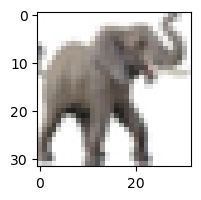

In [76]:
plt.figure(figsize=(15, 2))
plt.imshow(train_images[9])
print(train_labels[9])

## Normalize pixel values to be between 0 and 1

In [27]:
# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0


## build the Cnn model 

In [30]:

# Define the CNN model
cnn_model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(100)  # CIFAR-100 has 100 classes
])

# Compile the model
cnn_model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [31]:
cnn_model.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_15 (Conv2D)          (None, 30, 30, 32)        896       
                                                                 
 max_pooling2d_10 (MaxPooli  (None, 15, 15, 32)        0         
 ng2D)                                                           
                                                                 
 conv2d_16 (Conv2D)          (None, 13, 13, 64)        18496     
                                                                 
 max_pooling2d_11 (MaxPooli  (None, 6, 6, 64)          0         
 ng2D)                                                           
                                                                 
 conv2d_17 (Conv2D)          (None, 4, 4, 64)          36928     
                                                                 
 flatten_5 (Flatten)         (None, 1024)             

## Train the model

In [32]:
# Train the model
history = cnn_model.fit(train_images, train_labels, epochs=10)            

Epoch 1/10
1563/1563 [==============================] - 19s 12ms/step - loss: 3.9570 - accuracy: 0.0942
Epoch 2/10
1563/1563 [==============================] - 17s 11ms/step - loss: 3.2963 - accuracy: 0.2023
Epoch 3/10
1563/1563 [==============================] - 17s 11ms/step - loss: 2.9961 - accuracy: 0.2594
Epoch 4/10
1563/1563 [==============================] - 17s 11ms/step - loss: 2.8019 - accuracy: 0.2979
Epoch 5/10
1563/1563 [==============================] - 18s 11ms/step - loss: 2.6670 - accuracy: 0.3249
Epoch 6/10
1563/1563 [==============================] - 17s 11ms/step - loss: 2.5387 - accuracy: 0.3462
Epoch 7/10
1563/1563 [==============================] - 17s 11ms/step - loss: 2.4377 - accuracy: 0.3687
Epoch 8/10
1563/1563 [==============================] - 17s 11ms/step - loss: 2.3544 - accuracy: 0.3875
Epoch 9/10
1563/1563 [==============================] - 17s 11ms/step - loss: 2.2843 - accuracy: 0.4024
Epoch 10/10
1563/1563 [==============================] - 18s 11m

In [35]:
# Evaluate the model
test_loss, test_acc = cnn_model.evaluate(test_images, test_labels, verbose=2)
print(f"Test accuracy: {test_acc}")
print(f"Loss: {test_loss}")

313/313 - 1s - loss: 2.5630 - accuracy: 0.3527 - 1s/epoch - 4ms/step
Test accuracy: 0.35269999504089355
Loss: 2.5629680156707764


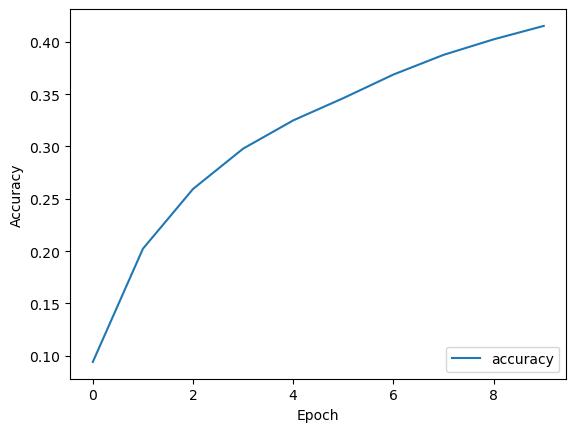

In [46]:
# Plot training history
plt.plot(history.history['accuracy'], label='accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.show()


In [44]:
y_pred = cnn_model.predict(test_images)
y_pred[:5]

313/313 [==============================] - 1s 4ms/step


array([[ -9.474086  ,  -7.3875833 ,  -3.6325524 ,  -3.2948198 ,
         -6.4920735 ,  -2.654448  ,  -7.6469502 ,  -2.8369155 ,
         -0.29022393,  -2.703375  ,  -6.702247  ,  -3.3881178 ,
         -0.8987002 ,  -2.6049526 ,  -6.3332753 ,  -6.746541  ,
         -3.9326355 ,  -2.685789  ,  -2.5623605 ,  -4.6049566 ,
         -4.985129  ,  -5.0021276 ,  -6.1641903 ,  -2.7826943 ,
         -2.6860147 ,  -4.0575166 ,  -6.7422514 ,  -3.8550448 ,
         -7.2150016 ,  -3.3024993 ,  -2.51876   ,  -4.707996  ,
         -4.1745067 ,  -5.5563116 ,  -5.8930173 ,  -4.030855  ,
         -9.248807  ,  -1.8981445 ,  -2.9259064 ,  -2.7491431 ,
         -2.2944608 ,  -1.1010098 ,  -8.060197  ,  -8.865856  ,
         -2.4110863 ,  -4.985998  ,  -2.0957222 ,  -6.222456  ,
         -4.1124787 ,  -1.853723  ,  -7.1863523 ,  -4.432096  ,
         -8.374949  , -11.881812  ,  -4.973985  ,  -2.9264464 ,
         -2.6225045 ,  -5.8871765 ,  -0.5312768 ,  -2.3416963 ,
         -5.9358916 ,  -7.6852593 ,  -9.

In [50]:
import numpy as np
prr = np.argmax(y_pred[1])
print(prr)


33


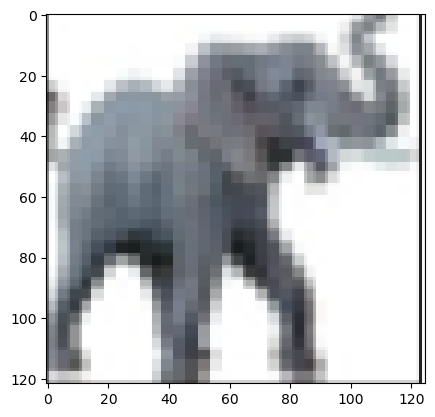

In [72]:
import cv2  
img = cv2.imread('testimg.png')
plt.imshow(img)

In [73]:
from keras.preprocessing.image import img_to_array, load_img
img = cv2.resize(img, (32, 32))  # Assuming the model expects input images of size 32x32

# Convert the image to array and normalize pixel values
img_array = img_to_array(img)
img_array = img_array / 255.0  # Normalize pixel values to [0, 1]

# Expand the dimensions to create a batch with a single sample
img_array = np.expand_dims(img_array, axis=0)

In [74]:
p= cnn_model.predict(img_array)

1/1 [==============================] - 0s 13ms/step


In [75]:
print(np.argmax(p))

31


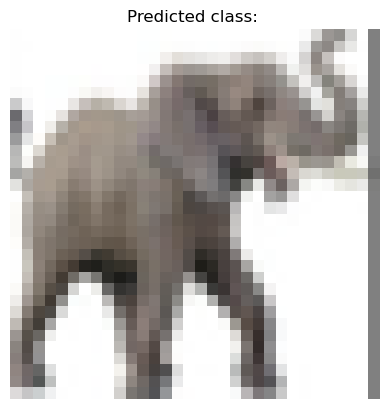

In [77]:


# Display the image with the predicted class label
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Predicted class: " )
plt.axis('off')
plt.show()